# CTU bus timetable optimisation: a bottom-up walkthrough

This notebook rebuilds the whole project from a 2-variable toy up to the real 68-route model.
Every code cell has a text cell **before** it (what we do and why) and a text cell **after** it (what the output means).

**Demand in this project is synthetic and illustrative.** Results show how the method behaves, not what CTU will achieve.

How to use it: run the cells from top to bottom (menu *Run → Run All*). The last section reruns the full project
pipeline in a temporary folder (about 4 minutes) and checks it reproduces the saved results.

Companion reading: `study_guide/textbook/textbook.pdf` (theory) and `study_guide/cheatsheet/cheatsheet.pdf`.

## 0. Setup

We import the libraries and the project's own code (`src/`). We also create a **running variable table**: every time
a new variable or parameter appears, we call `define(...)` to record its meaning, type, units and a typical value.
`show_vars()` prints the table so far.

In [1]:
import sys, math, itertools, time, shutil, subprocess, tempfile   # standard-library helpers
from dataclasses import replace                                  # copy a settings object with one field changed
from pathlib import Path

import numpy as np                       # arrays and maths
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # plots
import pulp                              # modelling library (talks to the HiGHS solver)

ROOT = Path.cwd().resolve().parents[1]   # this notebook lives in <project>/study_guide/notebook
sys.path.insert(0, str(ROOT))            # so "import src..." finds the project's code
from src import params as P, data as D, demand as DM, model as MD, metrics as MT
from src import goals as G, pareto as PA, simulate as S, calibration as CAL

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

VARS = []                                                   # the running variable table
def define(symbol, meaning, kind, units, typical):
    # kind: "decision variable", "parameter" or "result"
    VARS.append(dict(symbol=symbol, meaning=meaning, type=kind, units=units, typical=typical))
def show_vars():
    display(pd.DataFrame(VARS))

print("project root:", ROOT)
print("PuLP", pulp.__version__)

project root: C:\Users\armaa\OneDrive\Desktop\Minors
PuLP 4.0.1


**What this means.** The project folder was found and its modules loaded. If you see an error here, the notebook is
not inside `study_guide/notebook/` of the project, or a package is missing (`pip install -r requirements.txt`).

## 1. Units: headway and frequency

The **headway** $h$ is the minutes between buses. The **frequency** $f$ is buses per hour. Since an hour has
60 minutes, $f = 60/h$. The project keeps this conversion in one place, `src/params.py`.

In [2]:
define("h", "headway: minutes between buses", "decision (through the menu)", "min", "10-90")
define("f", "frequency = 60 / h", "derived from h", "dep/h", "0.67-6")
for h in [10, 15, 20, 30, 80]:
    f = P.headway_min_to_freq_per_h(h)          # the project's own conversion function
    print(f"headway {h:>3} min  ->  frequency {f:.2f} departures per hour")

headway  10 min  ->  frequency 6.00 departures per hour
headway  15 min  ->  frequency 4.00 departures per hour
headway  20 min  ->  frequency 3.00 departures per hour
headway  30 min  ->  frequency 2.00 departures per hour
headway  80 min  ->  frequency 0.75 departures per hour


**What this means.** Short headway = high frequency. Route 31's published 80-minute headway is only 0.75 buses per
hour. Remember: the *shortest* published headway gives the *highest* frequency $f_{\max}$.

## 2. Waiting time: why it is $h/2$, and why bunching makes it longer

We simulate passengers arriving at random times at a stop. Each waits for the next bus. First with perfectly regular
buses every 12 minutes, then with irregular gaps (gamma distribution with the same mean, CV = 0.3, as in Stage 6).
Theory says: regular → $h/2 = 6$ min; irregular → $(h/2)(1 + \mathrm{CV}^2) = 6 \times 1.09 = 6.54$ min.

In [3]:
define("CV", "coefficient of variation of the gaps between buses", "parameter", "-", "0.3")
rng = np.random.default_rng(0)                       # fixed seed: same numbers every run
h, cv = 12.0, 0.3

def mean_wait(bus_times, n_pax=200_000):
    arrivals = rng.uniform(0, bus_times[-1] - 1e-9, n_pax)      # random arrival moments
    nxt = np.searchsorted(bus_times, arrivals)                  # index of the next bus for each person
    return float((bus_times[nxt] - arrivals).mean())            # average wait

regular = np.arange(0, 100_000, h)                              # a bus exactly every 12 min
k = 1 / cv**2                                                   # gamma shape that gives CV = 0.3
gaps = rng.gamma(shape=k, scale=h / k, size=9000)               # random gaps with mean 12 min
irregular = np.concatenate([[0], np.cumsum(gaps)])

print(f"regular buses:   simulated {mean_wait(regular):.3f} min, theory h/2 = {h/2:.3f}")
print(f"irregular buses: simulated {mean_wait(irregular):.3f} min, theory (h/2)(1+CV^2) = {h/2*(1+cv**2):.3f}")

regular buses:   simulated 6.007 min, theory h/2 = 6.000


irregular buses: simulated 6.561 min, theory (h/2)(1+CV^2) = 6.540


**What this means.** The simulation matches both formulas to about two decimals. Irregular service costs extra
waiting with the *same number of buses*: this extra part is the **excess wait time** $(h/2)\mathrm{CV}^2$.
The model's waiting objective $Z_1$ uses $h/2$; the Stage 6 simulation multiplies by $1 + 0.3^2 = 1.09$.

## 3. A 2-variable linear program, by hand and in code

Teaching example (textbook Chapters 4-6). A depot has 10 buses for routes A and B.

| constraint | formula |
|---|---|
| fleet | $x_A + x_B \le 10$ |
| kilometres | $30x_A + 15x_B \le 250$ |
| route B terminal | $x_B \le 7$ |
| no negative buses | $x_A, x_B \ge 0$ |

Objective: maximise passengers carried $Z = 60x_A + 45x_B$.

**By hand:** the best answer of a linear program is at a corner. We compute every corner (where two border lines
cross), keep the feasible ones and evaluate $Z$.

In [4]:
define("x_A, x_B", "buses on toy routes A and B", "decision variable", "buses", "0-10")
# each border written as  a1*xA + a2*xB = b
borders = {"fleet": (1, 1, 10), "km": (30, 15, 250), "B limit": (0, 1, 7), "xA=0": (1, 0, 0), "xB=0": (0, 1, 0)}

def feasible(xa, xb, tol=1e-9):
    return xa >= -tol and xb >= -tol and xa + xb <= 10 + tol and 30*xa + 15*xb <= 250 + tol and xb <= 7 + tol

rows = []
for (n1, l1), (n2, l2) in itertools.combinations(borders.items(), 2):
    A = np.array([[l1[0], l1[1]], [l2[0], l2[1]]], float)
    if abs(np.linalg.det(A)) < 1e-12:                 # parallel lines never cross
        continue
    xa, xb = np.linalg.solve(A, [l1[2], l2[2]])       # crossing point of the two borders
    if feasible(xa, xb):
        rows.append(dict(borders=f"{n1} & {n2}", xA=round(xa, 3), xB=round(xb, 3), Z=round(60*xa + 45*xb, 2)))
corners = pd.DataFrame(rows).drop_duplicates(["xA", "xB"]).sort_values("Z", ascending=False)
corners

,borders,xA,xB,Z
0,fleet & km,6.667,3.333,550.0
2,km & xB=0,8.333,0.000,500.0
1,fleet & B limit,3.000,7.000,495.0
3,B limit & xA=0,0.000,7.000,315.0
4,xA=0 & xB=0,0.000,0.000,0.0


**What this means.** Five feasible corners (as in the textbook). The best is $x_A = 6.67$, $x_B = 3.33$ with
$Z = 550$. Now the same problem solved by the HiGHS solver through PuLP: it must give the same answer.

In [5]:
lp = pulp.LpProblem("two_routes_LP", pulp.LpMaximize)
xA = lp.add_variable("xA", 0, None)                  # continuous, lower bound 0, no upper bound
xB = lp.add_variable("xB", 0, None)
lp += 60*xA + 45*xB                                  # the objective
lp += xA + xB <= 10, "fleet"
lp += 30*xA + 15*xB <= 250, "km"
lp += xB <= 7, "B_terminal"
st = lp.solve(pulp.HiGHS(msg=False))
print("status:", st.status.name, "| xA =", round(xA.value(), 3), "| xB =", round(xB.value(), 3),
      "| Z =", round(pulp.value(lp.objective), 2))

status: Optimal | xA = 6.667 | xB = 3.333 | Z = 550.0


**What this means.** The solver agrees with the hand calculation: $Z = 550$ at $(6.67, 3.33)$. But 6.67 buses is
impossible. Next we draw the feasible region to see why the answer sits at that corner.

### Plot: the feasible region, step by step
1. Draw each constraint's border line.
2. Shade the polygon of points that obey all constraints (its corners are the table above).
3. Draw the objective line $60x_A + 45x_B = 550$ through the optimum.

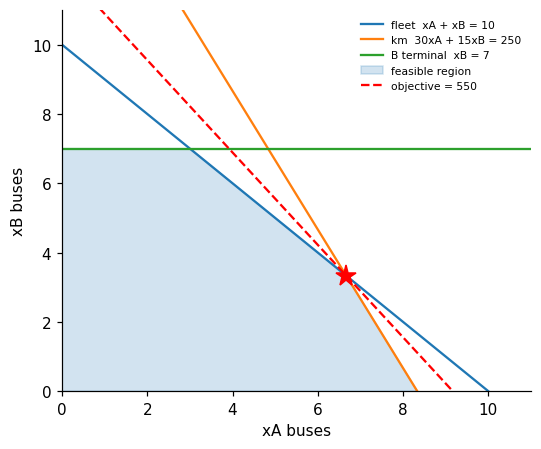

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
xs = np.linspace(0, 11, 100)
ax.plot(xs, 10 - xs, label="fleet  xA + xB = 10")                    # step 1
ax.plot(xs, (250 - 30*xs) / 15, label="km  30xA + 15xB = 250")
ax.axhline(7, color="tab:green", label="B terminal  xB = 7")
poly = corners.sort_values(["xA", "xB"])                               # step 2: order corners around the polygon
order = np.argsort(np.arctan2(poly.xB - poly.xB.mean(), poly.xA - poly.xA.mean()))
ax.fill(poly.xA.values[order], poly.xB.values[order], alpha=0.2, color="tab:blue", label="feasible region")
ax.plot(xs, (550 - 60*xs) / 45, "r--", label="objective = 550")        # step 3
ax.plot(20/3, 10/3, "r*", ms=14)
ax.set_xlim(0, 11); ax.set_ylim(0, 11); ax.set_xlabel("xA buses"); ax.set_ylabel("xB buses")
ax.legend(fontsize=7, frameon=False); plt.show()

**How to read this.** Across = buses on A, up = buses on B. The shaded shape is everything allowed. The red dashed
line has the same objective value everywhere along it; sliding it outward increases $Z$, and the last point of the
shape it touches is the optimum (red star). **Conclusion:** the fleet and km limits are both *binding* there.

## 4. Integer variables: whole buses

We repeat the problem with $x_A, x_B$ forced to be integers (a MILP). We also check by **brute force**: try every
whole-number pair and keep the best. Rounding the LP answer is not enough.

In [7]:
ip = pulp.LpProblem("two_routes_MILP", pulp.LpMaximize)
iA = ip.add_variable("xA", 0, None, cat="Integer")      # whole numbers only
iB = ip.add_variable("xB", 0, None, cat="Integer")
ip += 60*iA + 45*iB
ip += iA + iB <= 10
ip += 30*iA + 15*iB <= 250
ip += iB <= 7
ip.solve(pulp.HiGHS(msg=False))
print("MILP answer:", int(iA.value()), int(iB.value()), "Z =", pulp.value(ip.objective))

best = max(((a, b) for a in range(11) for b in range(11) if feasible(a, b)), key=lambda p: 60*p[0] + 45*p[1])
print("brute force:", best, "Z =", 60*best[0] + 45*best[1])
print("rounded LP (7, 3) feasible?", feasible(7, 3), "| km used:", 30*7 + 15*3)

MILP answer: 6 4 Z = 540.0
brute force: (6, 4) Z = 540
rounded LP (7, 3) feasible? False | km used: 255


**What this means.** The true integer optimum is $(6, 4)$ with $Z = 540$, found both by the solver (branch and bound)
and by brute force. Rounding $(6.67, 3.33)$ to $(7, 3)$ breaks the km limit (255 > 250). This is why the project uses
integer variables for buses instead of rounding.

## 5. One real route as a MILP: route 31 in the AM peak

Now the bus world. Route 31 (Omex Tower – Mansa Devi), AM peak, in the project's "relaxed" mode.

New quantities:
- **menu**: allowed headways {45, 60, 80} min; binary switch $y_k$ = 1 if headway $k$ is chosen; exactly one is 1.
- **cycle time** $\tau = 2 \times 37 / 22 \times 1.10 = 3.70$ h; buses needed $x \ge \tau f$ (C2).
- **bounds** $2 \le x \le 4$ (C5: stay close to today's 3 buses).
- **capacity** $C f$ with $C = 60$; **overflow** $o \ge D_\alpha - C f$, $o \ge 0$ (C3), with $D_\alpha = 129.5$ pax/h.

In [8]:
define("y_rtk", "1 if route r in period t uses headway k", "decision variable (binary)", "0/1", "0 or 1")
define("x_rt", "buses on route r in period t", "decision variable (integer)", "buses", "1-20")
define("o_rt", "overflow: planning demand above capacity", "decision variable (continuous)", "pax/h", "0-100")
define("tau_r", "cycle time = (2d or d)/v x 1.10", "parameter", "h", "0.5-4")
define("C", "bus capacity", "parameter", "pax/bus", "60")
define("D_alpha", "planning demand U - alpha (U - M)", "parameter", "pax/h", "1.175 x M")

menu, tau, M, Da, C, H, dcyc = [45, 60, 80], 2*37/22*1.10, 110.21, 129.50, 60, 3.0, 74.0
table = pd.DataFrame([dict(h=h, f=60/h, buses_needed=math.ceil(60/h*tau - 1e-9), allowed=math.ceil(60/h*tau - 1e-9) <= 4,
                           Z1_part=M*h/2, Z2_part=dcyc*60/h*H, Z3_part=max(0, Da - C*60/h)*H) for h in menu])
print(f"tau = {tau:.3f} h"); display(table.round(2))

m = pulp.LpProblem("route31_AM", pulp.LpMinimize)
y = {h: m.add_variable(f"y_{h}", 0, 1, cat="Binary") for h in menu}
x = m.add_variable("x", 2, 4, cat="Integer")                 # C5 bounds
o = m.add_variable("o", 0, None)                             # overflow, continuous
f = pulp.lpSum(60/h * y[h] for h in menu)                    # frequency: linear in the switches
m += pulp.lpSum(y.values()) == 1, "one_headway"
m += tau * f <= x, "C2_buses"
m += o >= Da - C * f, "C3_overflow"
m += o * H                                                   # objective: overflow passengers (Z3 part)
m.solve(pulp.HiGHS(msg=False))
chosen = [h for h in menu if y[h].value() > 0.5][0]
print("chosen headway:", chosen, "min | buses:", int(x.value()), "| overflow:", round(o.value(), 1), "pax/h")

tau = 3.700 h


,h,f,buses_needed,allowed,Z1_part,Z2_part,Z3_part
0,45,1.33,5,False,2479.72,296.0,148.5
1,60,1.00,4,True,3306.30,222.0,208.5
2,80,0.75,3,True,4408.40,166.5,253.5


chosen headway: 60 min | buses: 4 | overflow: 69.5 pax/h


**What this means.** The table lists every option. 45 min would cut overflow most but needs 5 buses, above the
bound of 4, so it is not allowed. The solver picks **60 min with 4 buses**, overflow 69.5 pax/h (208.5 passengers
over the 3-hour peak). This is exactly what the full project's P-BALANCED plan does for route 31
(`outputs/tables/gp_route_changes.csv`: 80 → 60 min, 3 → 4 buses).

## 6. Three toy routes, three periods, using the project's own model code

Now we build a small network with the **same code the real project uses** (`src/model.py`). Three routes A, B, C;
periods AM, Midday, PM; route C does not run in the PM peak. 12 buses in total. Menus come from the published ranges.
This toy is also used in the video (scene 6).

The three objectives:
- $Z_1 = \sum M \cdot h/2$: waiting [pax·min/h]
- $Z_2 = \sum d_{\text{cycle}} \cdot H \cdot f$: vehicle-km per day
- $Z_3 = \sum o \cdot H$: unserved passengers per day

In [9]:
define("M_rt", "most likely demand (synthetic)", "parameter", "pax/h", "3-160 (real)")
define("H_rt", "service hours of route r inside period t", "parameter", "h", "3 / 6 / 3")
define("Z1", "waiting = sum M h/2", "result (objective)", "pax*min/h", "~180,000 (real)")
define("Z2", "vehicle-km = sum d_cycle H f", "result (objective)", "veh-km/day", "~77,000 (real)")
define("Z3", "unserved = sum o H", "result (objective)", "pax/day", "~2,200-3,100 (real)")

periods = list(P.PERIODS)                                    # ['AM', 'Midday', 'PM']
toy_cfg = P.ModelConfig(C=60, spare_ratio=0.0, fleet_B=12, equity_mode="off", pract_abs=10, pract_rel=10,
                        pract_min=10, menu_min=(10, 15, 20, 30), equity_cap_min={"AM": 12, "Midday": 20, "PM": 12})
tau_t = np.array([1.0, 1.5, 0.8]); dcyc_t = np.array([20.0, 30.0, 16.0]); x0_t = np.array([4, 4, 3])
h_lo, h_hi = np.array([10.0, 15.0, 15.0]), np.array([20.0, 30.0, 30.0])
M_t = {(0, "AM"): 300, (0, "Midday"): 120, (0, "PM"): 250, (1, "AM"): 200, (1, "Midday"): 90, (1, "PM"): 210,
       (2, "AM"): 150, (2, "Midday"): 60, (2, "PM"): 0}
active = {(i, t): not (i == 2 and t == "PM") for i in range(3) for t in periods}
H_t = {(i, t): (P.PERIODS[t][1] - P.PERIODS[t][0]) if active[i, t] else 0.0 for i in range(3) for t in periods}
Da_t = {k: float(DM.alpha_cut_upper(1.35 * v, v, 0.5)) for k, v in M_t.items()}     # U = 1.35 M, alpha = 0.5
menu_t = {(i, t): MD.route_menu(h_lo[i], h_hi[i], toy_cfg, t) if active[i, t] else [] for i in range(3) for t in periods}
lb_t, ub_t = MD.practicality_bounds(x0_t, toy_cfg)
toy = MD.Instance(["A", "B", "C"], periods, tau_t, dcyc_t, x0_t, (60/h_hi + 60/h_lo)/2, 60/h_hi, 60/h_lo, h_lo, h_hi,
                  active, H_t, {k: float(v) for k, v in M_t.items()}, Da_t, menu_t, lb_t, ub_t, toy_cfg)
print("active route-periods:", toy.active_pairs())
print("menus:", {f"{toy.route_no[i]}-{t}": menu_t[i, t] for i, t in toy.active_pairs()})
print("usable fleet B_eff =", toy_cfg.B_eff)

active route-periods: [(0, 'AM'), (0, 'Midday'), (0, 'PM'), (1, 'AM'), (1, 'Midday'), (1, 'PM'), (2, 'AM'), (2, 'Midday')]
menus: {'A-AM': [10, 15, 20], 'A-Midday': [10, 15, 20], 'A-PM': [10, 15, 20], 'B-AM': [15, 20, 30], 'B-Midday': [15, 20, 30], 'B-PM': [15, 20, 30], 'C-AM': [15, 20, 30], 'C-Midday': [15, 20, 30]}
usable fleet B_eff = 12


**What this means.** 8 active route-periods, each with a menu of 3 headways, so there are $3^8 = 6561$ possible
timetables. Now we minimise $Z_3$ (unserved passengers) with the project's `build_model` and `solve`.

In [10]:
b = MD.build_model(toy, {"Z3": 1.0, "Z2": 1e-6, "fleet": 1e-4})      # same tie-breaks as Stage 3
res = MD.solve(b)
print("status:", res["status"], "| variables:", b.prob.numVariables(), "| constraints:", b.prob.numConstraints())
display(res["schedule"])
x_s, f_s = MD.schedule_to_arrays(toy, res["schedule"])
m_toy = MT.evaluate(toy, x_s, f_s)                                   # the project's evaluator
print({k: round(m_toy[k], 2) for k in ["Z1", "Z2", "Z3", "fleet_AM", "fleet_Midday", "fleet_PM", "mean_wait_min"]})
print("constraint violations:", len(MT.check_schedule(toy, x_s, f_s)))

status: Optimal | variables: 40 | constraints: 27


,route_no,period,headway_min,f,x,o
0,A,AM,10,6.0,6,0.00
1,A,Midday,20,3.0,3,0.00
2,A,PM,10,6.0,6,0.00
3,B,AM,30,2.0,3,115.00
4,B,Midday,30,2.0,3,0.00
5,B,PM,15,4.0,6,6.75
6,C,AM,20,3.0,3,0.00
7,C,Midday,30,2.0,2,0.00


{'Z1': 12275.0, 'Z2': 2316.0, 'Z3': 365.25, 'fleet_AM': 12, 'fleet_Midday': 8, 'fleet_PM': 12, 'mean_wait_min': 8.89}
constraint violations: 0


**What this means.** Each row is one route-period: chosen headway, frequency, buses and remaining overflow. Bus totals
per period stay within 12 (C1), and `check_schedule` finds no violations. Busy route A gets the shortest headway.

## 7. Fuzzy demand: the triangle and the $\alpha$-cut

Demand is uncertain, so each route-period has $(L, M, U)$ with $L = 0.8M$ and $U = 1.35M$. Capacity is planned for
$D_\alpha = U - \alpha(U - M)$. We draw the triangle for toy route A in the AM peak ($M = 300$).

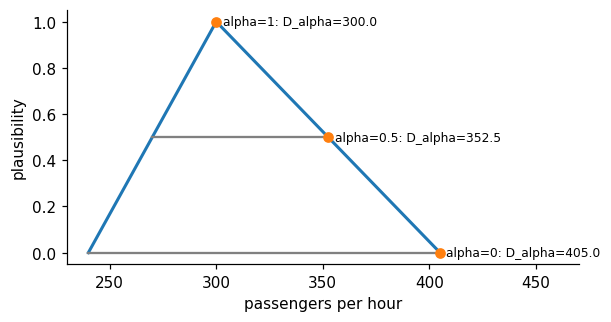

In [11]:
define("L, M, U", "lowest, most likely, highest demand", "parameter", "pax/h", "0.8M, M, 1.35M")
define("alpha", "cut level: 1 = most likely, 0 = most cautious", "parameter", "-", "0.5")
L_, M_, U_ = DM.tfn_from_modal(300.0)                                  # project function
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([L_, M_, U_], [0, 1, 0], lw=2)                                  # the triangle
for a in [0, 0.5, 1]:
    lo, up = DM.alpha_cut_lower(L_, M_, a), DM.alpha_cut_upper(U_, M_, a)
    ax.plot([lo, up], [a, a], color="grey"); ax.plot(up, a, "o", color="tab:orange")
    ax.text(up + 3, a, f"alpha={a}: D_alpha={float(up):.1f}", va="center", fontsize=8)
ax.set_xlabel("passengers per hour"); ax.set_ylabel("plausibility"); ax.set_xlim(230, 470); plt.show()

**How to read this.** Across = demand, up = how plausible it is (1 at the peak $M$). Each grey slice is an $\alpha$-cut;
orange dots are the planning demand. **Conclusion:** smaller $\alpha$ plans for more passengers. The project uses
$\alpha = 0.5$, i.e. $1.175 \times M$ (here 352.5).

## 8. Many objectives: enumerate all 6561 toy timetables and find the Pareto front

For each timetable we use the fewest buses that run it ($x = \lceil f\tau \rceil$), drop timetables that need more
than 12 buses in a period, and compute $(Z_1, Z_2, Z_3)$. A timetable is **Pareto-efficient** if no other is at least as
good on all three and better on one.

In [12]:
pairs = toy.active_pairs()
points, combos = [], []
for ch in itertools.product(*[toy.menu[p] for p in pairs]):          # every combination of headways
    f = {p: 60.0 / h for p, h in zip(pairs, ch)}
    x = {p: max(int(lb_t[p[0]]), math.ceil(f[p] * tau_t[p[0]] - 1e-9)) for p in pairs}
    if any(sum(x[p] for p in pairs if p[1] == t) > toy_cfg.B_eff for t in periods):
        continue                                                     # breaks the fleet limit C1
    m_ = MT.evaluate(toy, x, f)
    points.append([m_["Z1"], m_["Z2"], m_["Z3"]]); combos.append(ch)
points = np.array(points)
mask = PA.nondominated(points)                                       # project's dominance filter
print(f"{3**len(pairs)} combinations, {len(points)} respect the fleet, {mask.sum()} are Pareto-efficient")

6561 combinations, 2304 respect the fleet, 50 are Pareto-efficient


**What this means.** Many timetables are impossible (too many buses). Of the feasible ones, only a small set is
efficient: every other timetable is beaten by one of them on all three goals.

### Plot: waiting vs unserved, front highlighted
Step 1: grey dots = all feasible timetables. Step 2: blue = Pareto-efficient (in 3-D). Step 3: label axes.

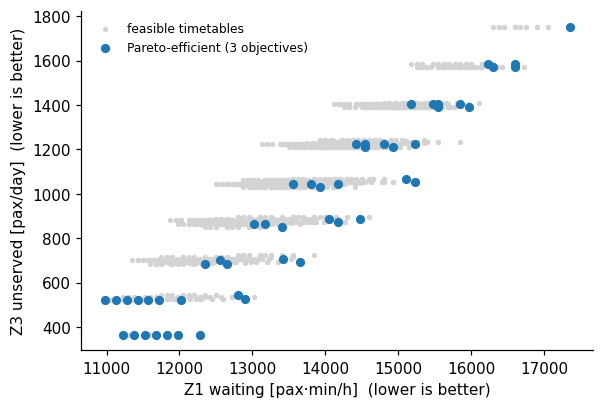

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(points[:, 0], points[:, 2], s=6, color="lightgrey", label="feasible timetables")
ax.scatter(points[mask, 0], points[mask, 2], s=25, color="tab:blue", label="Pareto-efficient (3 objectives)")
ax.set_xlabel("Z1 waiting [pax·min/h]  (lower is better)"); ax.set_ylabel("Z3 unserved [pax/day]  (lower is better)")
ax.legend(fontsize=8, frameon=False); plt.show()

**How to read this.** Lower-left is better on both axes. Blue points are the front; some look beaten in this 2-D view
because the third objective (vehicle-km) is hidden: they win on kilometres. **Conclusion:** there is no single best
timetable; picking one needs a preference, which is what goal programming adds.

## 9. Goal programming on the toy, checked by brute force

Goals (targets relative to the baseline = published mid frequencies):
G1 waiting ≤ 96% of baseline, G2 unserved = 0, G3 vehicle-km ≤ 97% of baseline, G4 headway ≤ cap.
Priority order P-PASSENGER: G2 > G1 > G4 > G3. We solve with the project's preemptive method (`src/goals.py`) and
compare with a brute-force lexicographic search over all timetables.

In [14]:
define("n_i, p_i", "under- / over-achievement of goal i", "decision variable", "goal unit", ">= 0")
define("T_i", "target of goal i (e.g. 0.96 x baseline waiting)", "parameter", "goal unit", "-")
tg = G.make_targets(toy, 0.04, 0.03)
levels = [["G2"], ["G1"], ["G4"], ["G3"]]
out = G.solve_preemptive(toy, tg, levels)
milp_dev = [r["achieved_dev"] for r in out["levels"]]

vecs = []                                                            # brute force: deviations of every timetable
for ch in itertools.product(*[toy.menu[p] for p in pairs]):
    f = {p: 60.0 / h for p, h in zip(pairs, ch)}
    x = {p: max(int(lb_t[p[0]]), math.ceil(f[p] * tau_t[p[0]] - 1e-9)) for p in pairs}
    if any(sum(x[p] for p in pairs if p[1] == t) > toy_cfg.B_eff for t in periods):
        continue
    dv = G.deviations_of(toy, tg, MT.evaluate(toy, x, f))
    vecs.append([dv[g[0]] for g in levels])
best = vecs
for k in range(len(levels)):                                         # keep the best at each level, in order
    mn = min(v[k] for v in best)
    best = [v for v in best if v[k] <= mn + 1e-6 * max(1, abs(mn))]
print(pd.DataFrame(dict(level=[1, 2, 3, 4], goal=[g[0] for g in levels], solver=np.round(milp_dev, 3),
                        brute_force=np.round(best[0], 3))))

   level goal  solver  brute_force
0      1   G2  365.25       365.25
1      2   G1  121.00       121.00
2      3   G4   29.00        29.00
3      4   G3  197.76       197.76


**What this means.** At every priority level the solver's unwanted deviation equals the brute-force best. The goal
programming code does exactly what it claims: it optimises goals in priority order and never lets a lower goal spoil
a higher one.

## 10. Scaling up: the real CTU data

Stage 1 reads `data/raw/CTU_Routes_Structured.xlsx`, checks it, and builds the route table.

In [15]:
define("d_r", "published route length", "parameter", "km", "3-45")
define("x0_r", "today's buses on route r", "parameter", "buses", "1-14")
define("B", "total fleet", "parameter", "buses", "389")
d = D.load_all()                                        # reads and validates the workbook
routes = d["routes"]
print(len(routes), "routes |", routes.x_base.sum(), "buses |", routes.d_r_km.sum(), "km |", len(d["stops"]), "stops")
display(routes[["route_no", "origin", "destination", "is_loop", "headway_min_lo", "headway_min_hi",
                "f_min", "f_max", "d_r_km", "x_base"]].head(8))

68 routes | 389 buses | 1662.0 km | 649 stops


,route_no,origin,destination,is_loop,headway_min_lo,headway_min_hi,f_min,f_max,d_r_km,x_base
0,1,New Maloya Colony,Manimajra,False,20.0,20.0,3.0,3.0,24.0,8
1,2A,Manimajra,Manimajra,True,20.0,25.0,2.4,3.0,38.3,6
2,2C,Mani Majra,Mani Majra,True,20.0,25.0,2.4,3.0,38.3,6
3,4A,ISBT-43,ISBT-43,True,25.0,25.0,2.4,2.4,32.5,4
4,4C,ISBT-43,ISBT-43,True,25.0,25.0,2.4,2.4,32.5,4
5,5A,RamDarbar,RamDarbar,True,15.0,30.0,2.0,4.0,38.4,8
6,5C,Ram Darbar,Ram Darbar,True,15.0,30.0,2.0,4.0,38.4,8
7,6,New Maloya Colony,Raipur Kalan,False,30.0,30.0,2.0,2.0,25.5,6


**What this means.** The counts match the timetable (68 routes, 389 buses, 1662 km, 649 stops); the code stops with an
error if they do not. Each route has a published headway range, a length and a bus allocation.

### Calibration: which reading of route length fits the fleet?
For each scenario (S1 full cycle, S2 one way) and speed, compute buses needed $\sum f_{\text{mid}} \tau$ and compare
with 389.

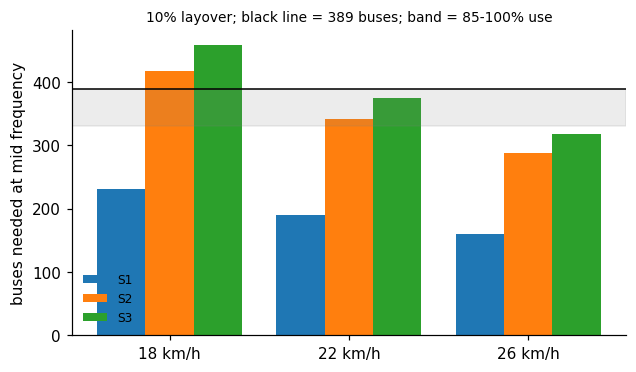

,scenario,v_kmh,N_need_fmid,utilisation
1,S1,18.0,231.119,0.594
3,S1,22.0,189.097,0.486
5,S1,26.0,160.006,0.411
7,S2,18.0,416.624,1.071
9,S2,22.0,340.874,0.876
11,S2,26.0,288.432,0.741
13,S3,18.0,458.286,1.178
15,S3,22.0,374.961,0.964
17,S3,26.0,317.275,0.816


In [16]:
grid = CAL.scenario_grid(routes)                      # every scenario x speed x layover
sub = grid[grid.layover_frac == 0.10]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
w = 0.27
for j, sc in enumerate(["S1", "S2", "S3"]):           # one bar group per speed, one bar per scenario
    s = sub[sub.scenario == sc]
    ax.bar(np.arange(3) + (j - 1) * w, s.N_need_fmid, width=w, label=sc)
ax.axhline(389, color="k", lw=1); ax.axhspan(0.85 * 389, 389, color="grey", alpha=0.15)
ax.set_xticks(range(3)); ax.set_xticklabels(["18 km/h", "22 km/h", "26 km/h"])
ax.set_ylabel("buses needed at mid frequency"); ax.legend(frameon=False, fontsize=8)
ax.set_title("10% layover; black line = 389 buses; band = 85-100% use", fontsize=9); plt.show()
display(sub[["scenario", "v_kmh", "N_need_fmid", "utilisation"]].round(3))

**How to read this.** Bars = buses the timetable needs; black line = buses that exist; grey band = plausible use.
S1 bars are far too low (half the fleet idle), so route length must be one way (S2). At 22 km/h S2 needs 340.9 buses
(88%): that is the project's choice. This is a simpler version of `outputs/figures/calibration_N_need.png`.

## 11. Real synthetic demand and the heatmap

Stage 2 builds the synthetic demand (recipe in textbook Chapter 13). We check route 31, then draw the heatmap step by
step: rows = routes, columns = periods, colour = most likely demand, grey = not running.

     period  active  H_t  overlap_h      L       M       U
198      AM       1  3.0        3.0  88.17  110.21  148.79
199  Midday       1  6.0        6.0  50.38   62.98   85.02
200      PM       1  3.0        3.0  81.87  102.34  138.16


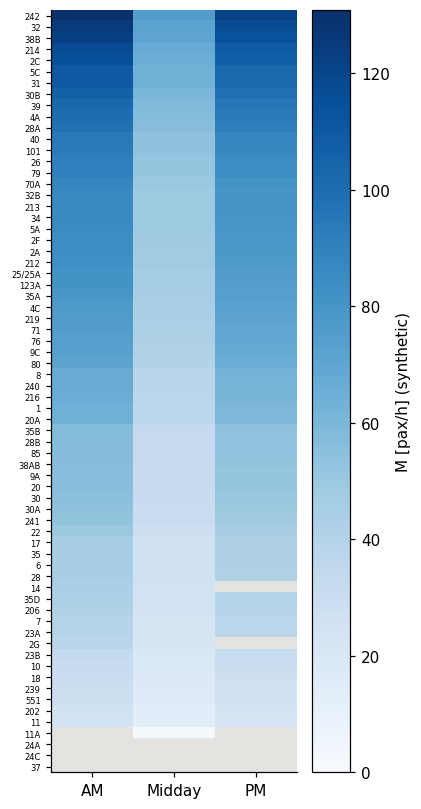

In [17]:
base, dem, per = DM.demand_table(d)                    # synthetic demand, seed 42
print(dem[dem.route_no == "31"][["period", "active", "H_t", "overlap_h", "L", "M", "U"]].round(2))
piv = dem.pivot(index="route_no", columns="period", values="M")[periods]          # step 1: table routes x periods
act = dem.pivot(index="route_no", columns="period", values="active")[periods]
order = piv.sort_values(["AM", "PM"], ascending=False).index                       # step 2: busiest first
vals = np.ma.masked_where(act.loc[order].to_numpy() == 0, piv.loc[order].to_numpy())  # step 3: hide inactive
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#e4e3df")
fig, ax = plt.subplots(figsize=(3.6, 9))
im = ax.imshow(vals, aspect="auto", cmap=cmap, vmin=0)                             # step 4: colour the cells
ax.set_xticks(range(3)); ax.set_xticklabels(periods); ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=5.5); fig.colorbar(im, ax=ax, label="M [pax/h] (synthetic)"); plt.show()

**How to read this.** Each row is a route, sorted busiest first. Darker = more passengers per hour; grey = the route
does not run then (not zero demand). **Conclusion:** midday is lighter everywhere (multiplier 0.8 vs 1.4 / 1.3), and
long routes through PGI and the ISBTs top the list. This is the synthetic recipe, not measured ridership.

## 12. The real MILP: baseline and minimum overflow

Same code as the toy, now with 68 routes. First the published timetable is **evaluated** (not optimised) and checked
against the constraints; then we minimise overflow $Z_3$ with published and with relaxed frequency limits.

In [18]:
define("B_eff", "usable fleet = floor((1 - s) B)", "parameter", "buses", "357")
inst_pub = MD.build_instance(routes, dem)                                     # default: published limits
print("active route-periods:", len(inst_pub.active_pairs()), "| B_eff:", inst_pub.cfg.B_eff)
xb, fb = MT.baseline_schedule(inst_pub)
base_m = MT.evaluate(inst_pub, xb, fb)
viol = MT.check_schedule(inst_pub, xb, fb)
print({k: round(base_m[k], 1) for k in ["Z1", "Z2", "Z3", "fleet_used", "mean_wait_min"]})
display(viol.groupby("constraint").agg(n=("excess", "size"), max_excess=("excess", "max")))

active route-periods: 191 | B_eff: 357
{'Z1': 184776.6, 'Z2': 79478.3, 'Z3': 3086.2, 'fleet_used': 385, 'mean_wait_min': 16.6}


,n,max_excess
constraint,,
C1 fleet,3,28.000
C2 f*tau <= x,9,1.425
C5 equity (soft),10,30.000


**What this means.** Today's timetable: waiting $Z_1 = 184{,}777$, vehicle-km 79,478, unserved 3,086 per day, 385 buses.
It breaks C1 (385 > 357 buses) in 3 periods, C2 in 9 places (routes 40, 76, 25/25A lack buses at 22 km/h), and the
soft equity cap in 10. It is the reference point for every comparison.

In [19]:
TIE = {"Z3": 1.0, "Z2": 1e-6, "fleet": 1e-4}
rows = []
for mode in ["published", "relaxed"]:
    inst_m = MD.build_instance(routes, dem, P.ModelConfig(fmax_mode=mode))
    bm = MD.build_model(inst_m, TIE)
    r = MD.solve(bm)
    xs, fs = MD.schedule_to_arrays(inst_m, r["schedule"])
    mm = MT.evaluate(inst_m, xs, fs)
    rows.append(dict(mode=mode, variables=bm.prob.numVariables(), constraints=bm.prob.numConstraints(),
                     solve_s=round(r["wall_s"], 2), Z1=mm["Z1"], Z2=mm["Z2"], Z3=mm["Z3"], fleet=mm["fleet_used"]))
display(pd.DataFrame(rows).round(1))
print("saved Stage 3 output:"); display(pd.read_csv(ROOT / "outputs" / "baseline_metrics.csv")[["schedule", "Z1", "Z2", "Z3", "fleet_used"]].round(1))

,mode,variables,constraints,solve_s,Z1,Z2,Z3,fleet
0,published,651,576,1.1,191482.1,75034.9,3066.6,355
1,relaxed,1015,576,0.2,180321.7,75676.5,2209.9,357


saved Stage 3 output:


,schedule,Z1,Z2,Z3,fleet_used
0,published baseline,184776.6,79478.3,3086.2,385
1,min Z3 (MILP),191482.1,75034.9,3066.6,355
2,"min Z3 (MILP, relaxed f_max)",180321.7,75676.5,2209.9,357


**What this means.** With published limits the model has 651 variables and 576 constraints and solves in well under a
second, but overflow only drops from 3,086 to 3,067: the crowded routes are already at their highest allowed frequency.
Relaxing $f_{\max}$ by two menu levels (1,015 variables) brings it to about 2,210. The numbers match the saved
`outputs/baseline_metrics.csv`.

## 13. The real goal programming: five priority scenarios

Relaxed limits, $\alpha = 0.5$, targets from `config/gp_scenarios.json` ($\kappa_1 = 0.04$, $\kappa_3 = 0.03$).

In [20]:
cfg_r = P.ModelConfig(fmax_mode="relaxed", alpha=0.5)
inst = MD.build_instance(routes, dem, cfg_r)
gp_cfg = G.load_config()
tg_r = G.targets_from_config(inst, gp_cfg)
bm_r = tg_r.baseline
res_rows, scheds = [], {}
for sc in gp_cfg["scenarios"]:
    o_ = G.run_scenario(inst, tg_r, sc)
    xs, fs = MD.schedule_to_arrays(inst, o_["result"]["schedule"])
    mm = MT.evaluate(inst, xs, fs)
    scheds[sc["name"]] = sc
    res_rows.append(dict(scenario=sc["name"], **{f"pct_{z}": 100 * (mm[z] - bm_r[z]) / bm_r[z] for z in ["Z1", "Z2", "Z3"]},
                         equity_excess_min=mm["equity_excess_min"], fleet=mm["fleet_used"]))
gp_tab = pd.DataFrame(res_rows); display(gp_tab.round(2))

,scenario,pct_Z1,pct_Z2,pct_Z3,equity_excess_min,fleet
0,P-PASSENGER,-3.98,-2.53,-29.59,100.0,357
1,P-OPERATOR,-3.81,-3.01,-29.59,100.0,357
2,P-EQUITY,-4.02,-3.07,-26.45,0.0,357
3,P-BALANCED,-4.05,-3.06,-26.45,0.0,357
4,CHEBYSHEV,-3.84,-3.00,-29.59,100.0,357


**What this means.** Every scenario uses 357 buses (vs 385 today), cuts waiting by about 4% and unserved passengers by
26-30%. Scenarios that put equity high (P-EQUITY, P-BALANCED) remove every minute above the headway cap but accept a
little more overflow. These match `outputs/gp_report.md`.

### Plot: % change vs today, grouped bars
One group per scenario, one bar per objective. Below zero is better.

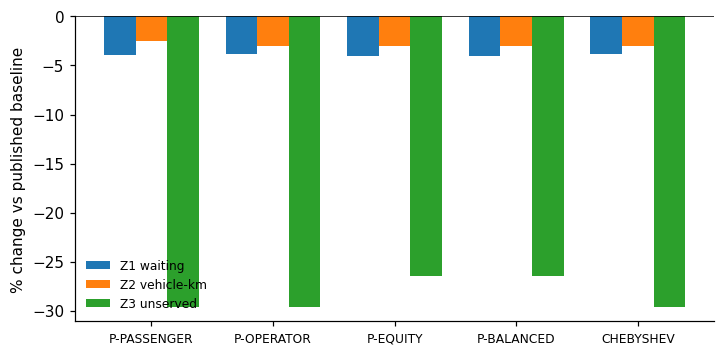

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
xs_ = np.arange(len(gp_tab)); w = 0.26
for j, (col, lab) in enumerate([("pct_Z1", "Z1 waiting"), ("pct_Z2", "Z2 vehicle-km"), ("pct_Z3", "Z3 unserved")]):
    ax.bar(xs_ + (j - 1) * w, gp_tab[col], width=w, label=lab)
ax.axhline(0, color="k", lw=1); ax.set_xticks(xs_); ax.set_xticklabels(gp_tab.scenario, fontsize=8)
ax.set_ylabel("% change vs published baseline"); ax.legend(frameon=False, fontsize=8); plt.show()

**How to read this.** Bars below the zero line are improvements. The big green-like bars are overflow cuts; waiting
and vehicle-km bars are small but negative. **Conclusion:** the priorities change the answer only slightly; all five
are clearly better than today on all three objectives (synthetic demand).

## 14. The real Pareto front: a small exact grid and a short genetic algorithm

The project uses a 20 × 20 AUGMECON grid (about 60 s) and NSGA-II with population 200, 300 generations, 5 seeds.
To keep this notebook quick we run a 5 × 5 grid and NSGA-II with population 40 for 30 generations, then compare
with the saved full results.

In [22]:
t0 = time.perf_counter()
pay, ideal, nadir, pay_hw = PA.lexicographic_payoff(inst, return_headways=True)       # payoff table (9 solves)
grid5, eps5, eps5_hw = PA.augmecon(inst, ideal, nadir, n_grid=5, eps=1e-3, extra_headways=pay_hw)
print(f"AUGMECON 5x5: {len(eps5)} efficient points in {time.perf_counter() - t0:.1f} s")
display(pay.round(1))

enc = PA.make_encoding(inst, {"Z1": bm_r["Z1"], "Z2": bm_r["Z2"], "Z3": bm_r["Z3"]})
t0 = time.perf_counter()
ga = PA.nsga2(enc, seed=1, pop_size=40, n_gen=30)
print(f"NSGA-II (40 x 30): {len(ga['front'])} points, {ga['n_eval']} evaluations, {time.perf_counter() - t0:.1f} s")
ref = np.full(3, 1.1)
print("hypervolume exact 5x5:", round(PA.hypervolume(PA.normalise(eps5.to_numpy(), ideal, nadir), ref), 3),
      "| NSGA-II short run:", round(PA.hypervolume(PA.normalise(ga["front"], ideal, nadir), ref), 3))
print("exact points strictly beaten by NSGA-II:", PA.n_strictly_dominated(ga["front"], eps5.to_numpy()))

AUGMECON 5x5: 6 efficient points in 21.4 s


,minimised,Z1,Z2,Z3
0,Z1,175794.9,77440.1,2321.3
1,Z2,193752.9,74501.1,3286.4
2,Z3,177430.2,77466.1,2173.1


NSGA-II (40 x 30): 40 points, 1240 evaluations, 3.8 s
hypervolume exact 5x5: 0.76 | NSGA-II short run: 0.83
exact points strictly beaten by NSGA-II: 0


**What this means.** The payoff table gives the ideal (diagonal) and nadir (worst per column). Even a tiny grid gives
proven-efficient points, and the short genetic algorithm beats none of them (strict-dominance count 0). In the full
project: 46 exact points (hypervolume 0.946), 611 NSGA-II points (0.980), still 0 exact points beaten.

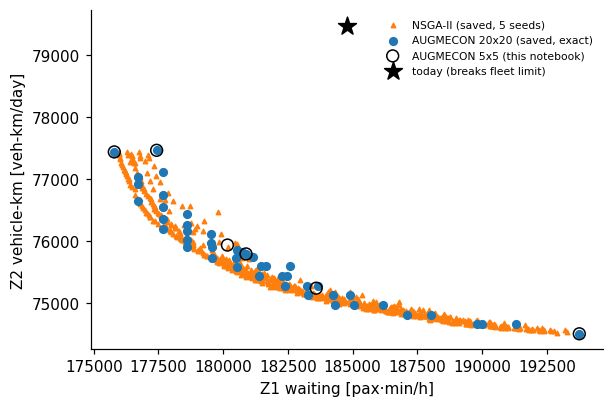

In [23]:
eps_full = pd.read_csv(ROOT / "outputs" / "pareto_eps.csv")
nsga_full = pd.read_csv(ROOT / "outputs" / "pareto_nsga2.csv")
nsga_u = nsga_full[PA.nondominated(nsga_full[["Z1", "Z2", "Z3"]].to_numpy())]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(nsga_u.Z1, nsga_u.Z2, s=8, marker="^", color="tab:orange", label="NSGA-II (saved, 5 seeds)")
ax.scatter(eps_full.Z1, eps_full.Z2, s=25, color="tab:blue", label="AUGMECON 20x20 (saved, exact)")
ax.scatter(eps5.Z1, eps5.Z2, s=60, facecolors="none", edgecolors="k", label="AUGMECON 5x5 (this notebook)")
ax.scatter([bm_r["Z1"]], [bm_r["Z2"]], marker="*", s=150, color="k", label="today (breaks fleet limit)")
ax.set_xlabel("Z1 waiting [pax·min/h]"); ax.set_ylabel("Z2 vehicle-km [veh-km/day]"); ax.legend(fontsize=7, frameon=False)
plt.show()

**How to read this.** Both axes are lower-is-better. The curve going down to the right is the trade-off: less
waiting costs more kilometres. Orange triangles and blue dots lie on the same curve (the two methods agree); the
notebook's circles sit on it too. The star (today) is far up and right. Only 2 of 3 objectives are shown, so some
points look dominated while being efficient in 3-D.

## 15. Simulation: 2000 random days

Stage 6 draws demand for 2000 days (triangular per route-period × a common daily shock, seed 2026) and evaluates
today's timetable and P-BALANCED on the **same** days.

In [24]:
define("N", "number of simulated days", "parameter", "days", "2000")
L, Mm, U = S.tfn_arrays(inst, dem)                      # per active route-period
Dsim = S.draw_demand(L, Mm, U)                          # 2000 x 191 matrix of demand [pax/h]
s_base = S.baseline(inst)
s_bal, status = S.from_gp(inst, "P-BALANCED (α=0.5)", scheds["P-BALANCED"], gp_cfg["kappa1"], 0.5, gp_cfg["kappa3"])
summ = {}
for s in [s_base, s_bal]:
    per_, _ = S.simulate(inst, s, Dsim)
    summ[s.name] = dict(wait=per_["mean_wait_min"].mean(), overflow=per_["overflow_pax"].mean(),
                        vkm=per_["vehicle_km"].mean(), fleet=per_["fleet_used"].mean(),
                        P_bad=(per_["overflow_share"] > 0.05).mean())
    summ[s.name]["_share"] = per_["overflow_share"]
tab = pd.DataFrame({k: {m: v for m, v in d_.items() if m != "_share"} for k, d_ in summ.items()}).T
display(tab.round(3))
saved = pd.read_csv(ROOT / "outputs" / "tables" / "simulation_tradeoffs.csv").set_index("schedule")
print("saved:", saved.loc[["Baseline", "P-BALANCED (α=0.5)"], ["mean_wait_min", "overflow_pax", "P_overflow_gt_5pct"]].round(3).to_dict("index"))

,wait,overflow,vkm,fleet,P_bad
Baseline,17.938,2248.813,79478.289,385.0,0.656
P-BALANCED (α=0.5),17.343,1586.311,77045.463,357.0,0.028


saved: {'Baseline': {'mean_wait_min': 17.938, 'overflow_pax': 2248.813, 'P_overflow_gt_5pct': 0.656}, 'P-BALANCED (α=0.5)': {'mean_wait_min': 17.343, 'overflow_pax': 1586.311, 'P_overflow_gt_5pct': 0.028}}


**What this means.** On the same 2000 days, P-BALANCED waits 17.34 vs 17.94 min (-3.3%), leaves about 30% fewer
passengers without room, drives 3% fewer km and uses 357 instead of 385 buses. A "bad day" (more than 5% of passengers
not fitting) happens on 65.6% of days today and about 3% with P-BALANCED. The numbers reproduce the saved outputs.

C:\Users\armaa\AppData\Local\Temp\ipykernel_20860\2380815463.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, labels=list(summ))   # box 25-75%, whiskers 5-95%


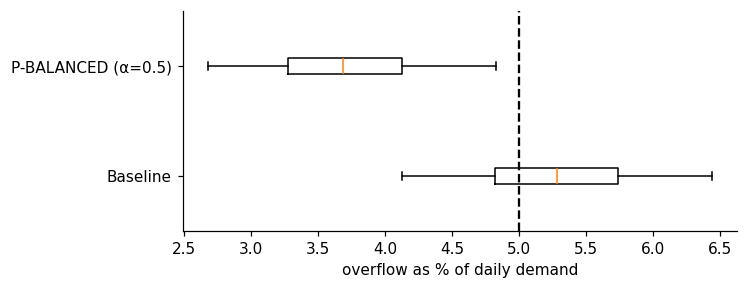

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
data = [100 * summ[k]["_share"] for k in summ]
ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, labels=list(summ))   # box 25-75%, whiskers 5-95%
ax.axvline(5, color="k", ls="--"); ax.set_xlabel("overflow as % of daily demand"); plt.show()

**How to read this.** Each box holds the middle half of the 2000 days, the line inside is the median, whiskers reach
the 5th and 95th percentiles; the dashed line is the 5% threshold. **Conclusion:** today's box sits mostly to the
right of 5%; P-BALANCED's box is well to the left.

### Tornado chart from the saved sensitivity analysis
Rerunning every setting takes a while, so we read `outputs/sensitivity_oat.csv` and draw the bars ourselves:
one row per assumption, bar from the base result to the result at the low and high values.

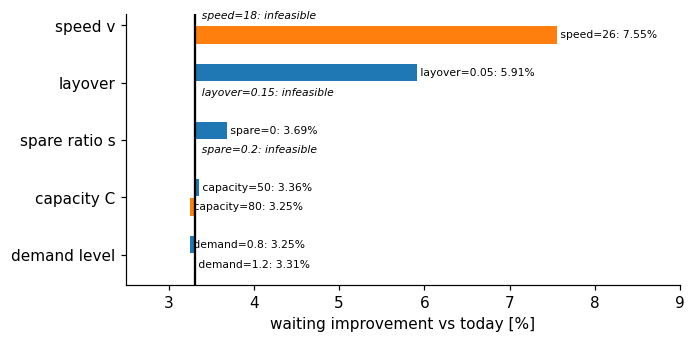

In [26]:
oat = pd.read_csv(ROOT / "outputs" / "sensitivity_oat.csv")
base_imp = oat[(oat.factor == "demand level") & (oat.value == 1.0)].wait_improvement_pct.iloc[0]
spec = [("speed v", 18, 26), ("layover", 0.05, 0.15), ("spare ratio s", 0.0, 0.2), ("capacity C", 50, 80),
        ("demand level", 0.8, 1.2)]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for j, (fac, lo, hi) in enumerate(spec):
    g = oat[oat.factor == fac].set_index("value")
    for v, dy, c in [(lo, -0.17, "tab:blue"), (hi, 0.17, "tab:orange")]:
        r = g.loc[v]
        if bool(r.feasible):
            ax.barh(j + dy, r.wait_improvement_pct - base_imp, left=base_imp, height=0.3, color=c)
            ax.text(r.wait_improvement_pct, j + dy, f" {fac.split()[0]}={v:g}: {r.wait_improvement_pct:.2f}%", va="center", fontsize=7)
        else:
            ax.text(base_imp, j + dy, f"  {fac.split()[0]}={v:g}: infeasible", va="center", fontsize=7, style="italic")
ax.axvline(base_imp, color="k"); ax.set_yticks(range(len(spec))); ax.set_yticklabels([s[0] for s in spec])
ax.invert_yaxis(); ax.set_xlabel("waiting improvement vs today [%]"); ax.set_xlim(2.5, 9); plt.show()

**How to read this.** The black line is the base result (3.31% less waiting). Blue = low value of the assumption,
orange = high value; long bars mean the result depends strongly on that assumption. **Conclusion:** speed and layover
dominate (26 km/h gives 7.55%; 18 km/h and 15% layover are infeasible); demand level and bus capacity hardly matter.

## 16. Same idea, bigger: toy vs real

| | toy (sections 6-9) | real project |
|---|---|---|
| routes × periods | 3 × 3, 8 active | 68 × 3, 191 active |
| menu per route-period | 3 headways | 3-12 headways |
| timetables possible | 6,561 (brute force works) | astronomically many (brute force impossible) |
| fleet | 12 | 357 usable (389 total) |
| model code | `src/model.py` | the same `src/model.py` |
| goal programming | checked against brute force | same code, 50 runs |
| Pareto front | full enumeration | AUGMECON 20×20 + NSGA-II |
| solve time | milliseconds | under 1 s per MILP |

The toy is the real model with smaller sets. Because brute force confirms the toy, and the real model uses the same
code, we can trust the real results (within their assumptions).

## 17. The full pipeline

Finally we run the whole project, `run_all.py`, exactly as it is shipped. To avoid overwriting the saved results it
runs in a **temporary copy** of the project. Then we compare its outputs with the saved ones. Only solver run times
may differ. This takes about 4 minutes.

In [27]:
tmp = Path(tempfile.mkdtemp(prefix="ctu_"))
for item in ["src", "config", "run_all.py"]:
    src_p = ROOT / item
    (shutil.copytree(src_p, tmp / item, ignore=shutil.ignore_patterns("__pycache__")) if src_p.is_dir()
     else shutil.copy(src_p, tmp / item))
(tmp / "data" / "raw").mkdir(parents=True)
shutil.copy(ROOT / "data" / "raw" / "CTU_Routes_Structured.xlsx", tmp / "data" / "raw")
t0 = time.perf_counter()
run = subprocess.run([sys.executable, "run_all.py"], cwd=tmp, capture_output=True, text=True)
print("exit code", run.returncode, f"in {(time.perf_counter() - t0) / 60:.1f} min")
print("\n".join(run.stdout.splitlines()[-6:]))

exit code 0 in 7.2 min
2026-10-16 12:10:42,657 INFO    stage6: sensitivity spare ratio s=0.08: wait improvement 3.31%
2026-10-16 12:10:42,707 INFO    stage6: sensitivity spare ratio s=0.1: INFEASIBLE
2026-10-16 12:10:42,752 INFO    stage6: sensitivity spare ratio s=0.2: INFEASIBLE
2026-10-16 12:10:43,988 INFO    stage6: sensitivity layover=0.05: wait improvement 5.91%
2026-10-16 12:10:45,364 INFO    stage6: sensitivity layover=0.1: wait improvement 3.31%
2026-10-16 12:10:45,439 INFO    stage6: sensitivity layover=0.15: INFEASIBLE


In [28]:
checks = []
for f in ["baseline_metrics.csv", "gp_results.csv", "pareto_eps.csv", "simulation_summary.csv", "sensitivity_oat.csv",
          "sensitivity_alpha.csv", "sensitivity_out_of_sample.csv"]:
    a, b_ = pd.read_csv(tmp / "outputs" / f), pd.read_csv(ROOT / "outputs" / f)
    cols = [c for c in a.columns if "wall" not in c and "runtime" not in c]     # timings always differ
    same = a[cols].round(6).equals(b_[cols].round(6))
    checks.append(dict(file=f, rows=len(a), identical_except_timings=same))
display(pd.DataFrame(checks))
shutil.rmtree(tmp, ignore_errors=True)

,file,rows,identical_except_timings
0,baseline_metrics.csv,3,True
1,gp_results.csv,60,True
2,pareto_eps.csv,46,True
3,simulation_summary.csv,156,True
4,sensitivity_oat.csv,19,True
5,sensitivity_alpha.csv,5,True
6,sensitivity_out_of_sample.csv,24,True


**What this means.** A fresh run of the full project reproduces every saved result (only solve times differ), because
every random step uses a fixed seed. This is the strongest reproducibility check you can show an audience.

## 18. The final variable table
Every symbol introduced in this notebook, with meaning, type, units and typical values.

In [29]:
show_vars()

,symbol,meaning,type,units,typical
0,h,headway: minutes between buses,decision (through the menu),min,10-90
1,f,frequency = 60 / h,derived from h,dep/h,0.67-6
2,CV,coefficient of variation of the gaps between b...,parameter,-,0.3
3,"x_A, x_B",buses on toy routes A and B,decision variable,buses,0-10
4,y_rtk,1 if route r in period t uses headway k,decision variable (binary),0/1,0 or 1
5,x_rt,buses on route r in period t,decision variable (integer),buses,1-20
6,o_rt,overflow: planning demand above capacity,decision variable (continuous),pax/h,0-100
7,tau_r,cycle time = (2d or d)/v x 1.10,parameter,h,0.5-4
8,C,bus capacity,parameter,pax/bus,60
9,D_alpha,planning demand U - alpha (U - M),parameter,pax/h,1.175 x M


**Remember for the presentation:** the demand is synthetic. The method, the code and its checks are real; the size
of the improvements depends on demand data CTU would need to supply.